# Novapolis Résilience : Planification des Secours et Réseau Urbain Résilient
### Projet Intégrateur en Algorithmique et Théorie des Graphes (Conformité PROJET.pdf — Barème 20 points)

Ce notebook rassemble l'intégralité des modules développés avec la bibliothèque standard Python (sans NetworkX) :
1. **Étape 1** : Chargement et validation stricte des données CSV.
2. **Étape 2** : Module 1 — Diagnostic d'accessibilité (DFS, BFS, cycles, composantes).
3. **Étape 3** : Modules 2 & 3 — Itinéraires des secours (Dijkstra, Bellman-Ford, Floyd-Warshall, circuits absorbants).
4. **Étape 4** : Module 4 — Arbres couvrants minimaux de fibre (Kruskal, Prim) et réparation de panne.
5. **Étape 5** : Module 5 — Comparaison des scénarios de crise et benchmarks de complexité.
6. **Étape 6** : Tests unitaires automatisés et animations graphiques.


In [1]:
# 1. Génération automatique de tous les jeux de données CSV
%run src/generator.py


NOVAPOLIS RÉSILIENCE : GÉNÉRATION DES JEUX DE DONNÉES CSV

[1/4] Génération du jeu manuel (data/manuel)...
      -> 8 sites, vérifiable sur papier.

[2/4] Génération du jeu réaliste documenté (data/realiste)...
      -> 110 sites, 5 districts, multi-scénarios.

[3/4] Génération du jeu synthétique d'échelle (data/synthetique)...
      -> 1000 sites, graine aléatoire fixée (seed 42).

[4/4] Génération des jeux de test pour circuits absorbants...
      -> data/test_absorbant_accessible (accessible depuis la source).
      -> data/test_absorbant_non_accessible (non accessible depuis la source).

GÉNÉRATION TERMINÉE AVEC SUCCÈS POUR TOUS LES JEUX DE DONNÉES !


In [2]:
# 2. Chargement et validation du réseau urbain réaliste (110 sites)
from src.data_manager import charger_reseau, appliquer_scenario

reseau = charger_reseau('data/realiste')
print(f'Sites chargés       : {len(reseau.routier.sommets())}')
print(f'Routes orientées    : {len(reseau.routier.tous_les_arcs())}')
print(f'Liaisons de fibre   : {len(reseau.fibre.toutes_les_aretes())}')
print(f'Demandes urgence    : {len(reseau.demandes)}')
print(f'Scénarios de crise  : {list(reseau.scenarios.keys())}')


Sites chargés       : 110
Routes orientées    : 424
Liaisons de fibre   : 155
Demandes urgence    : 26
Scénarios de crise  : ['scenario_normal', 'scenario_fermeture_pont', 'scenario_panne_fibre_dorsale', 'scenario_inondation_sud']


In [ ]:
# TABLEAU DE BORD INTERACTIF EN TEMPS RÉEL (HTML5 / CANVAS / DIJKSTRA ANIMÉ)
# Permet de tester, choisir le scénario, zoomer et lancer la simulation en direct !
import threading
import time
import socket
from IPython.display import IFrame, display
from src.web_dashboard import lancer_serveur

def demarrer_dashboard_local(port=8000):
    s = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    try:
        s.bind(('', port))
        s.close()
        t = threading.Thread(target=lancer_serveur, args=(port,), daemon=True)
        t.start()
        time.sleep(0.5)
    except OSError:
        pass  # Déjà en écoute

demarrer_dashboard_local(8000)
print('Tableau de bord interactif disponible sur : http://localhost:8000')
display(IFrame(src='http://localhost:8000', width='100%', height=650))


In [3]:
# 3. Module 1 : Diagnostic d'accessibilité (DFS, BFS, cycles orientés, sites isolés)
from src.accessibility import diagnostic_accessibilite, itineraire_min_arcs

diag = diagnostic_accessibilite(reseau.routier, reseau.fibre)
print('--- DIAGNOSTIC D ACCESSISIBILITÉ ---')
print(f'Taux d accès secours  : {diag["taux_accessibilite_globale"]*100:.1f}%')
print(f'Sites sensibles       : {diag["nb_sensibles_accessibles"]}/{diag["nb_sites_sensibles"]}')
print(f'Composantes fibre     : {diag["nb_composantes_fibre"]} (Tailles: {diag["tailles_composantes_fibre"]})')
print(f'Présence cycles       : {diag["presence_cycle_oriente"]}')

# Calcul d'un itinéraire minimisant le nombre d'arcs via BFS
itin_bfs = itineraire_min_arcs(reseau.routier, 'SITE_001', 'SITE_027')
print(f'\nItinéraire minimum en arcs (SITE_001 -> SITE_027) : {itin_bfs["chemin"]} ({itin_bfs["nb_arcs"]} arcs, durée {itin_bfs["temps_normal"]} min)')


--- DIAGNOSTIC D ACCESSISIBILITÉ ---
Taux d accès secours  : 94.5%
Sites sensibles       : 91/96
Composantes fibre     : 2 (Tailles: [109, 1])
Présence cycles       : True

Itinéraire minimum en arcs (SITE_001 -> SITE_027) : ['SITE_001', 'SITE_027'] (1 arcs, durée 7.65 min)


In [4]:
# 4. Modules 2 & 3 : Plus courts chemins et Détection des circuits absorbants
from src.shortest_paths import dijkstra, bellman_ford, floyd_warshall, evaluer_demande_intervention

# Test de Dijkstra vs Bellman-Ford sur le réseau normal
dist_dijk, _ = dijkstra(reseau.routier, 'SITE_001')
res_bf = bellman_ford(reseau.routier, 'SITE_001')
print(f'Distance SITE_001 -> SITE_027 (Dijkstra)    : {dist_dijk["SITE_027"]:.2f} min')
print(f'Distance SITE_001 -> SITE_027 (Bellman-Ford): {res_bf["distances"]["SITE_027"]:.2f} min')
print(f'Circuit absorbant accessible depuis SITE_001 : {res_bf["circuit_absorbant_accessible"]}')

# Évaluation des demandes en situation de crise (Fermeture du pont stratégique)
reseau_perturbe = appliquer_scenario(reseau, 'scenario_fermeture_pont')
print('\n--- ÉVALUATION DES PREMIÈRES DEMANDES (SCÉNARIO FERMETURE PONT) ---')
for dem in reseau.demandes[:5]:
    ev = evaluer_demande_intervention(reseau.routier, reseau_perturbe.routier, dem)
    print(f'Demande {dem.id} ({dem.origine}->{dem.destination}) : Avant={ev["cout_avant"]} min, Après={ev["cout_apres"]} min, Statut={ev["statut"]}')


Distance SITE_001 -> SITE_027 (Dijkstra)    : 7.65 min
Distance SITE_001 -> SITE_027 (Bellman-Ford): 7.65 min
Circuit absorbant accessible depuis SITE_001 : False

--- ÉVALUATION DES PREMIÈRES DEMANDES (SCÉNARIO FERMETURE PONT) ---
Demande DEM_001 (SITE_001->SITE_092) : Avant=13.44 min, Après=13.44 min, Statut=accessible
Demande DEM_002 (SITE_106->SITE_043) : Avant=25.28 min, Après=None min, Statut=inaccessible
Demande DEM_003 (SITE_001->SITE_020) : Avant=7.94 min, Après=7.94 min, Statut=accessible
Demande DEM_004 (SITE_001->SITE_043) : Avant=12.35 min, Après=12.35 min, Statut=accessible
Demande DEM_005 (SITE_001->SITE_015) : Avant=6.74 min, Après=6.74 min, Statut=accessible


In [5]:
# 5. Module 4 : Arbre couvrant minimal (Kruskal, Prim) et réparation de panne
from src.spanning_tree import kruskal, prim, comparer_kruskal_prim, simuler_panne_troncon

comp = comparer_kruskal_prim(reseau.fibre)
print(f'Coût total MST (Kruskal) : {comp["cout_kruskal"]} k€ ({comp["nb_aretes_kruskal"]} tronçons)')
print(f'Coût total MST (Prim)    : {comp["cout_prim"]} k€ ({comp["nb_aretes_prim"]} tronçons)')
print(f'Égalité stricte des coûts: {comp["couts_egaux"]}')

# Simulation de rupture sur une liaison majeure de l arbre
res_k = kruskal(reseau.fibre)
troncon_panne = res_k['aretes'][0].extremites()
res_panne = simuler_panne_troncon(reseau.fibre, res_k['aretes'], troncon_panne)
print(f'\nRupture du câble {troncon_panne} (coût initial: {res_panne["cout_arete_initiale"]} k€) :')
print(f'  -> Câble de remplacement optimal : {res_panne["arete_remplacement"]} (coût: {res_panne["cout_remplacement"]} k€)')
print(f'  -> Surcoût pour le réseau       : +{res_panne["surcout"]} k€')
print(f'  -> Nouveau coût de l arbre réparé: {res_panne["cout_total_nouvel_arbre"]} k€')


Coût total MST (Kruskal) : 1798.0 k€ (108 tronçons)
Coût total MST (Prim)    : 1798.0 k€ (108 tronçons)
Égalité stricte des coûts: True

Rupture du câble ('SITE_001', 'SITE_004') (coût initial: 8.0 k€) :
  -> Câble de remplacement optimal : None (coût: None k€)
  -> Surcoût pour le réseau       : +None k€
  -> Nouveau coût de l arbre réparé: 1790.0 k€


In [6]:
# 6. Module 5 : Analyse comparative des scénarios de crise et résilience
from src.resilience import comparer_tous_les_scenarios, afficher_tableau_resilience

rapport_resilience = comparer_tous_les_scenarios(reseau)
afficher_tableau_resilience(rapport_resilience)


SCÉNARIO                       | DEM. PERDUES  | RETARD MOY  | RETARD MAX  | SENSIBLES %  | FIBRE COMP
---------------------------------------------------------------------------------------------------------
scenario_normal                | 0 (0.0%)      | +0.0 min    | +0.0 min    | 94.8%        | 2 (1798.0 k€)
scenario_fermeture_pont        | 4 (15.38%)    | +0.0 min    | +0.0 min    | 94.8%        | 2 (1798.0 k€)
scenario_panne_fibre_dorsale   | 0 (0.0%)      | +0.0 min    | +0.0 min    | 94.8%        | 2 (1798.0 k€)
scenario_inondation_sud        | 0 (0.0%)      | +1.65 min   | +10.8 min   | 94.8%        | 2 (1804.9 k€)


Graphique 1 : Plus courts chemins (Dijkstra vs Bellman-Ford vs Floyd-Warshall)


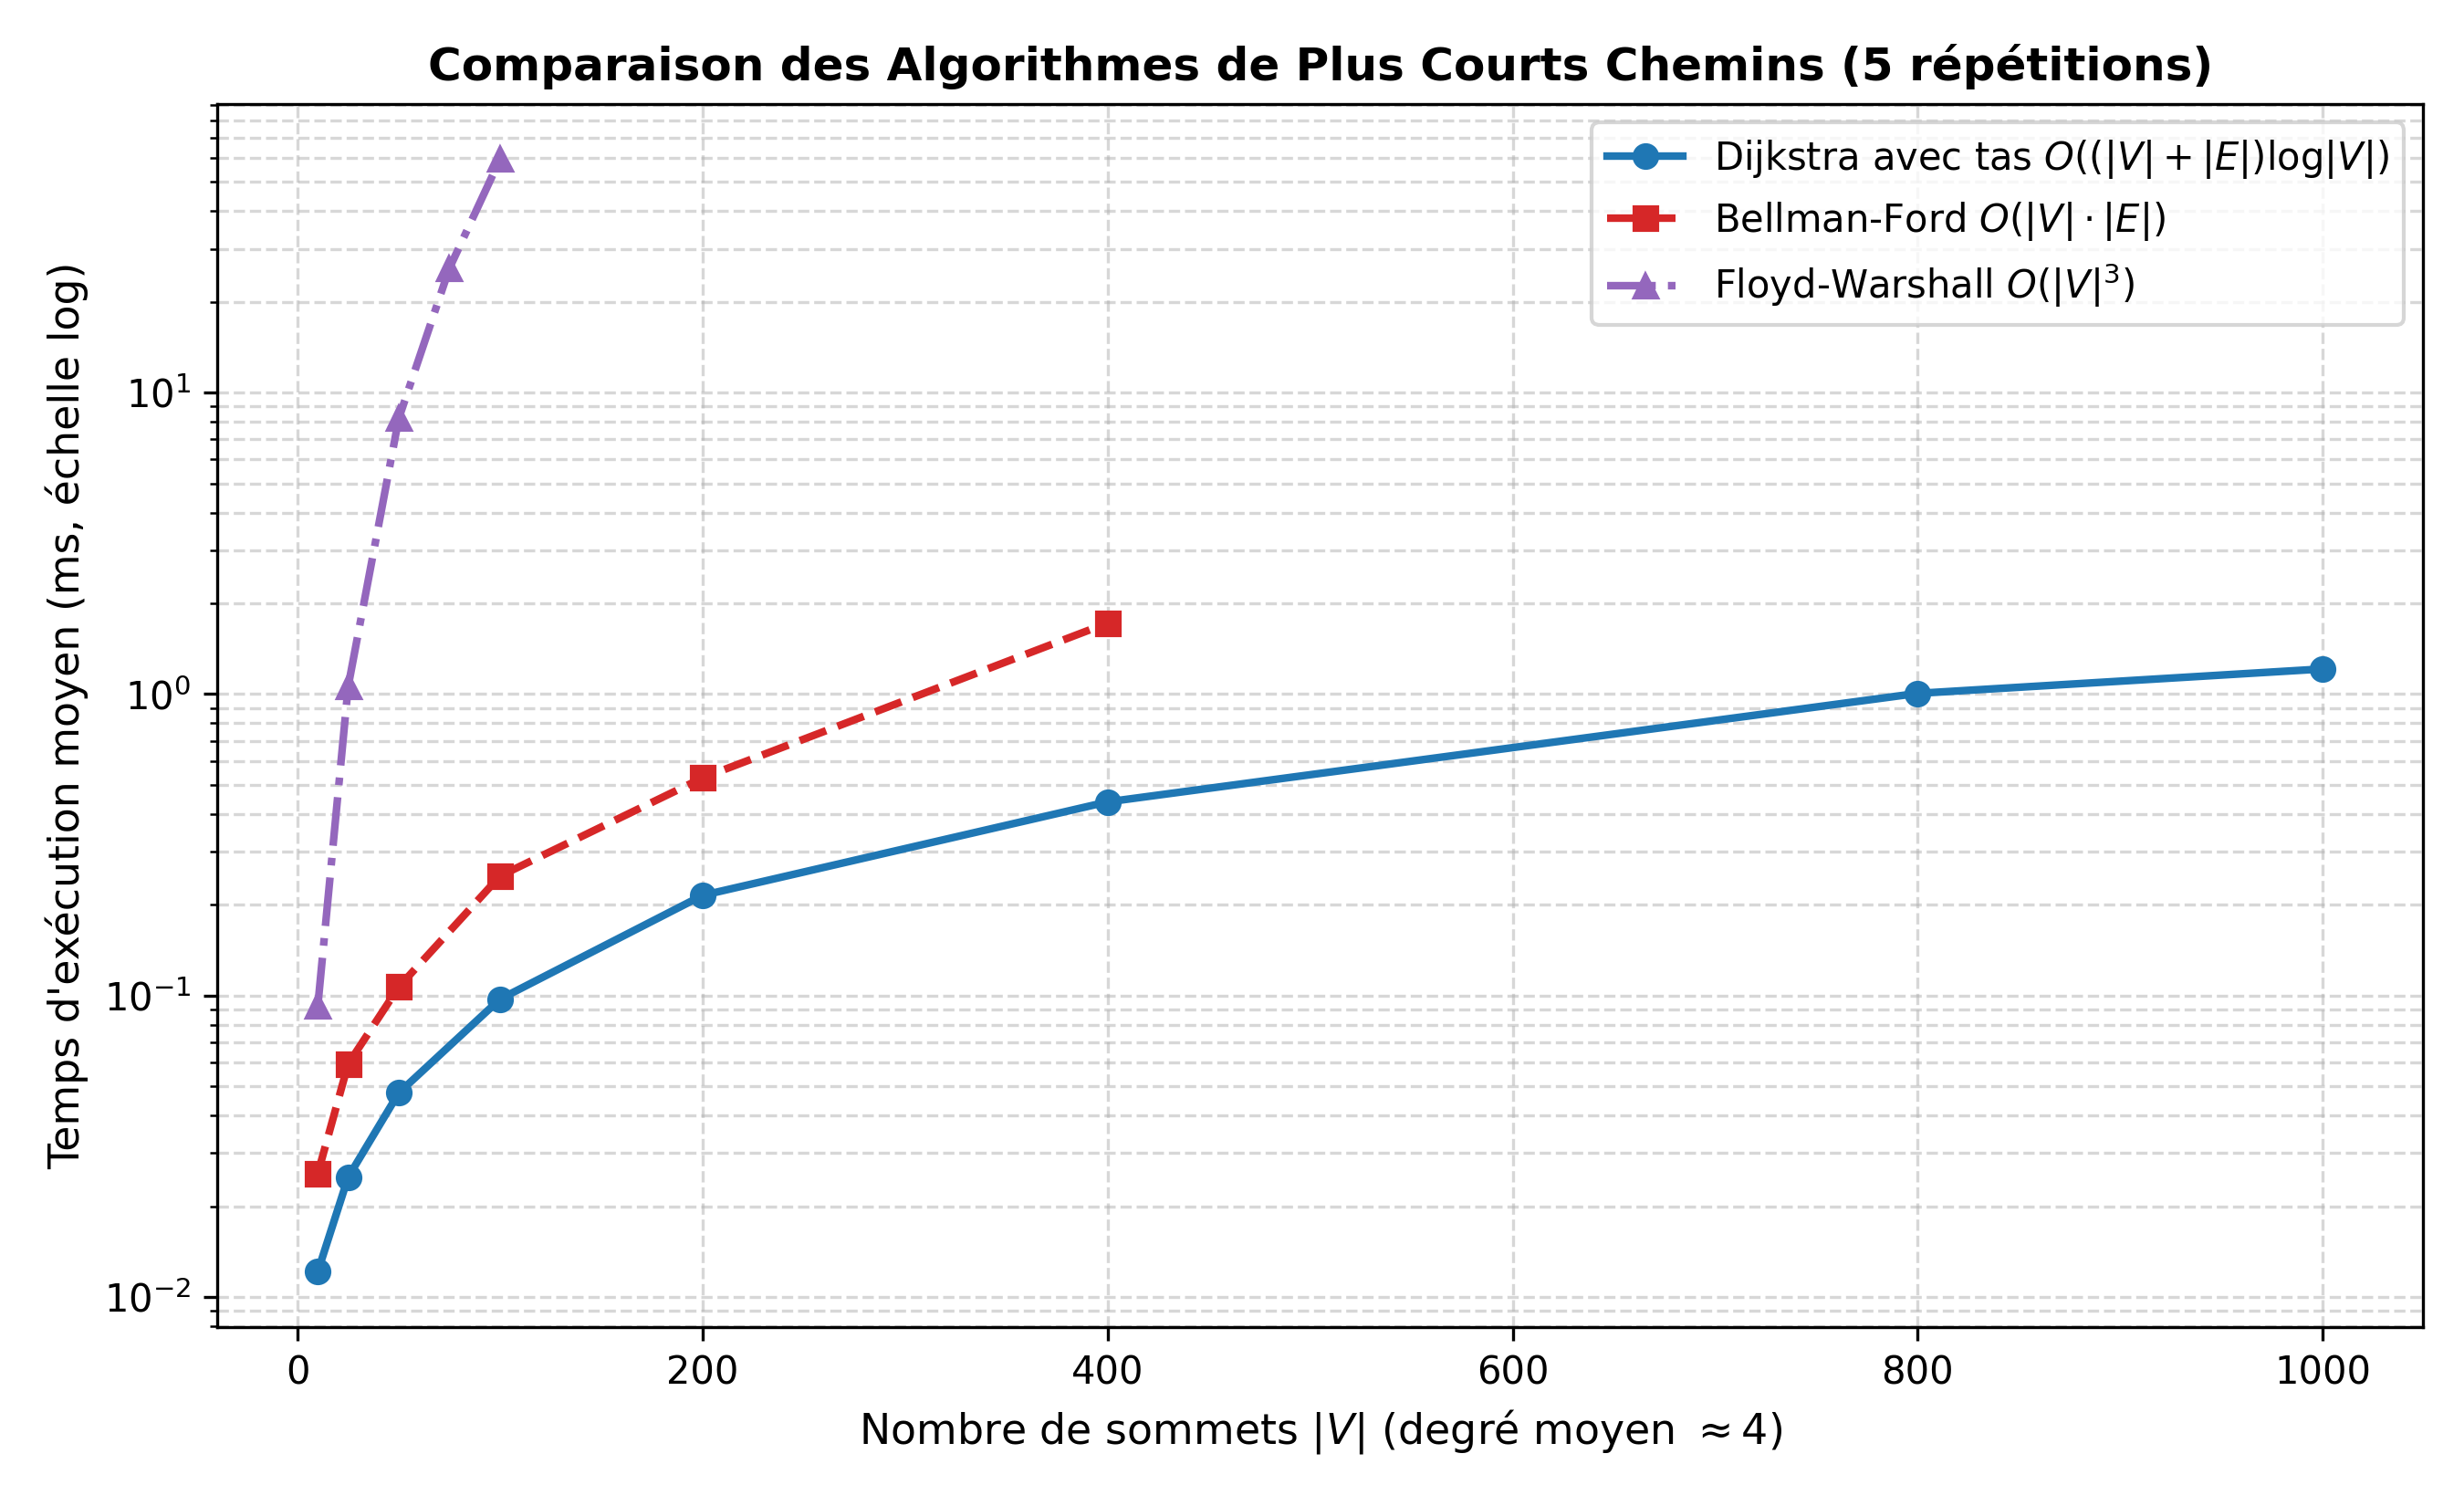

Graphique 2 : Arbres couvrants minimaux (Kruskal vs Prim)


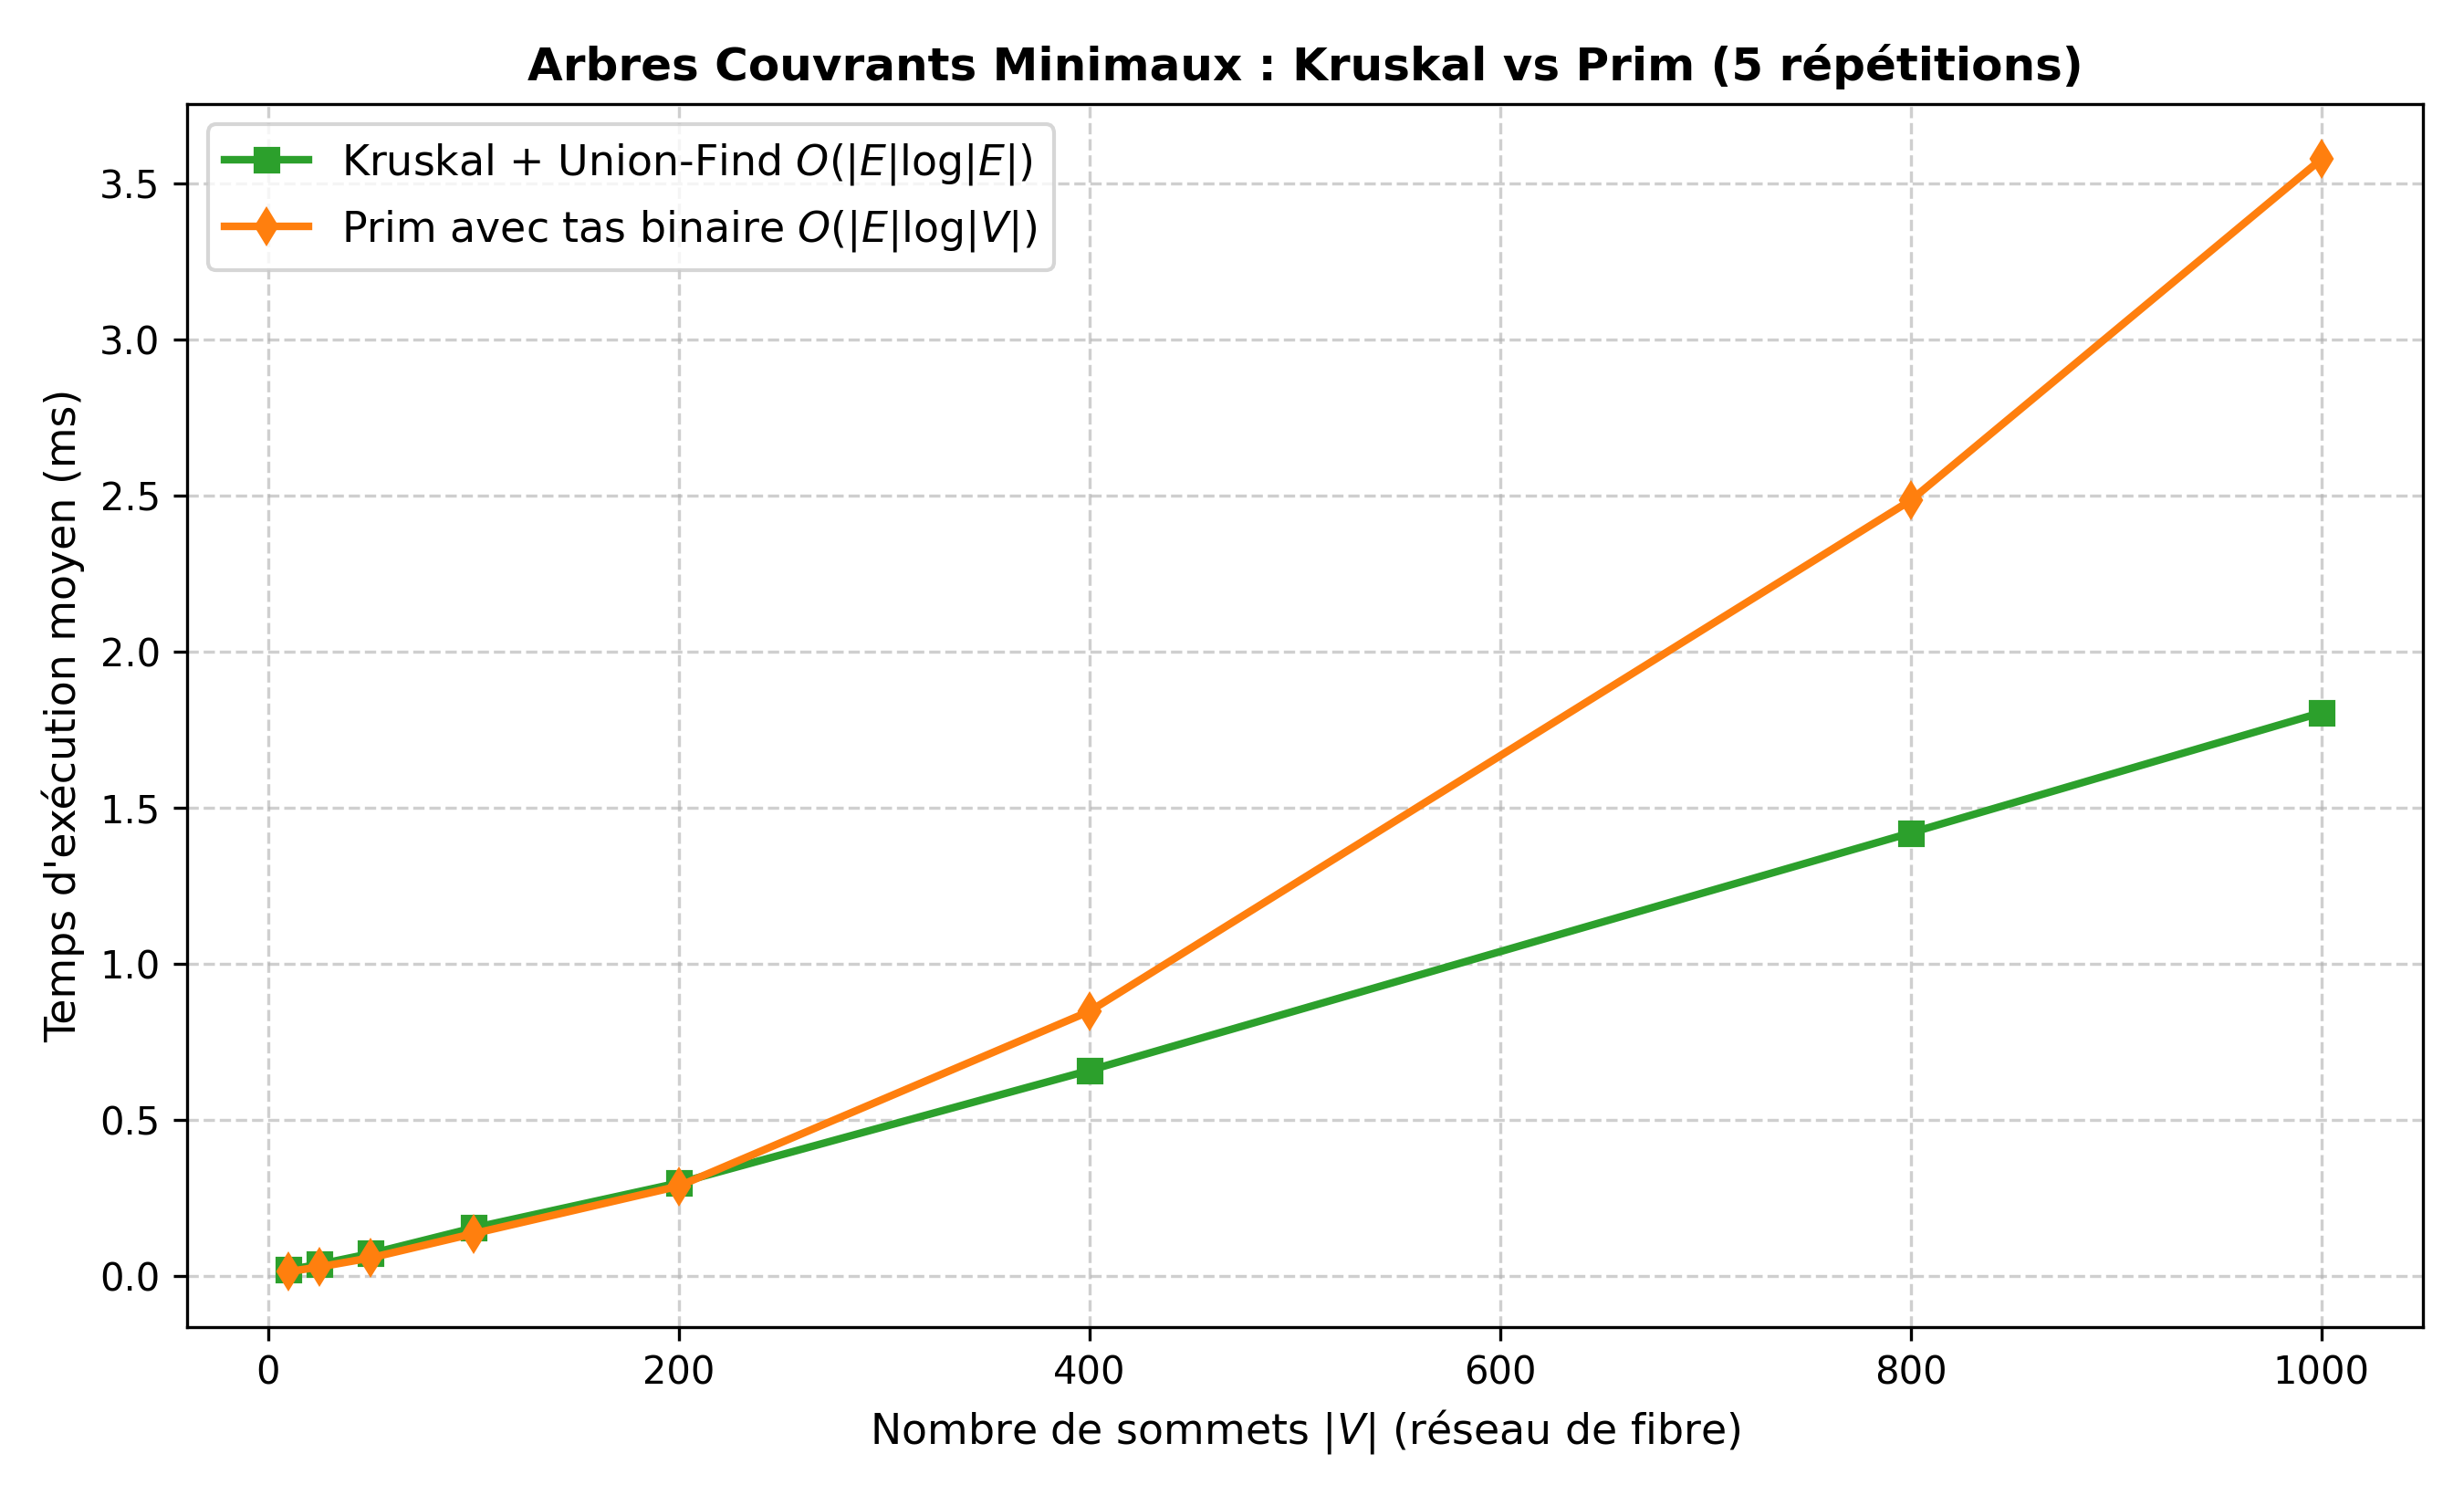

Graphique 3 : Parcours DFS/BFS et sensibilité à la densité


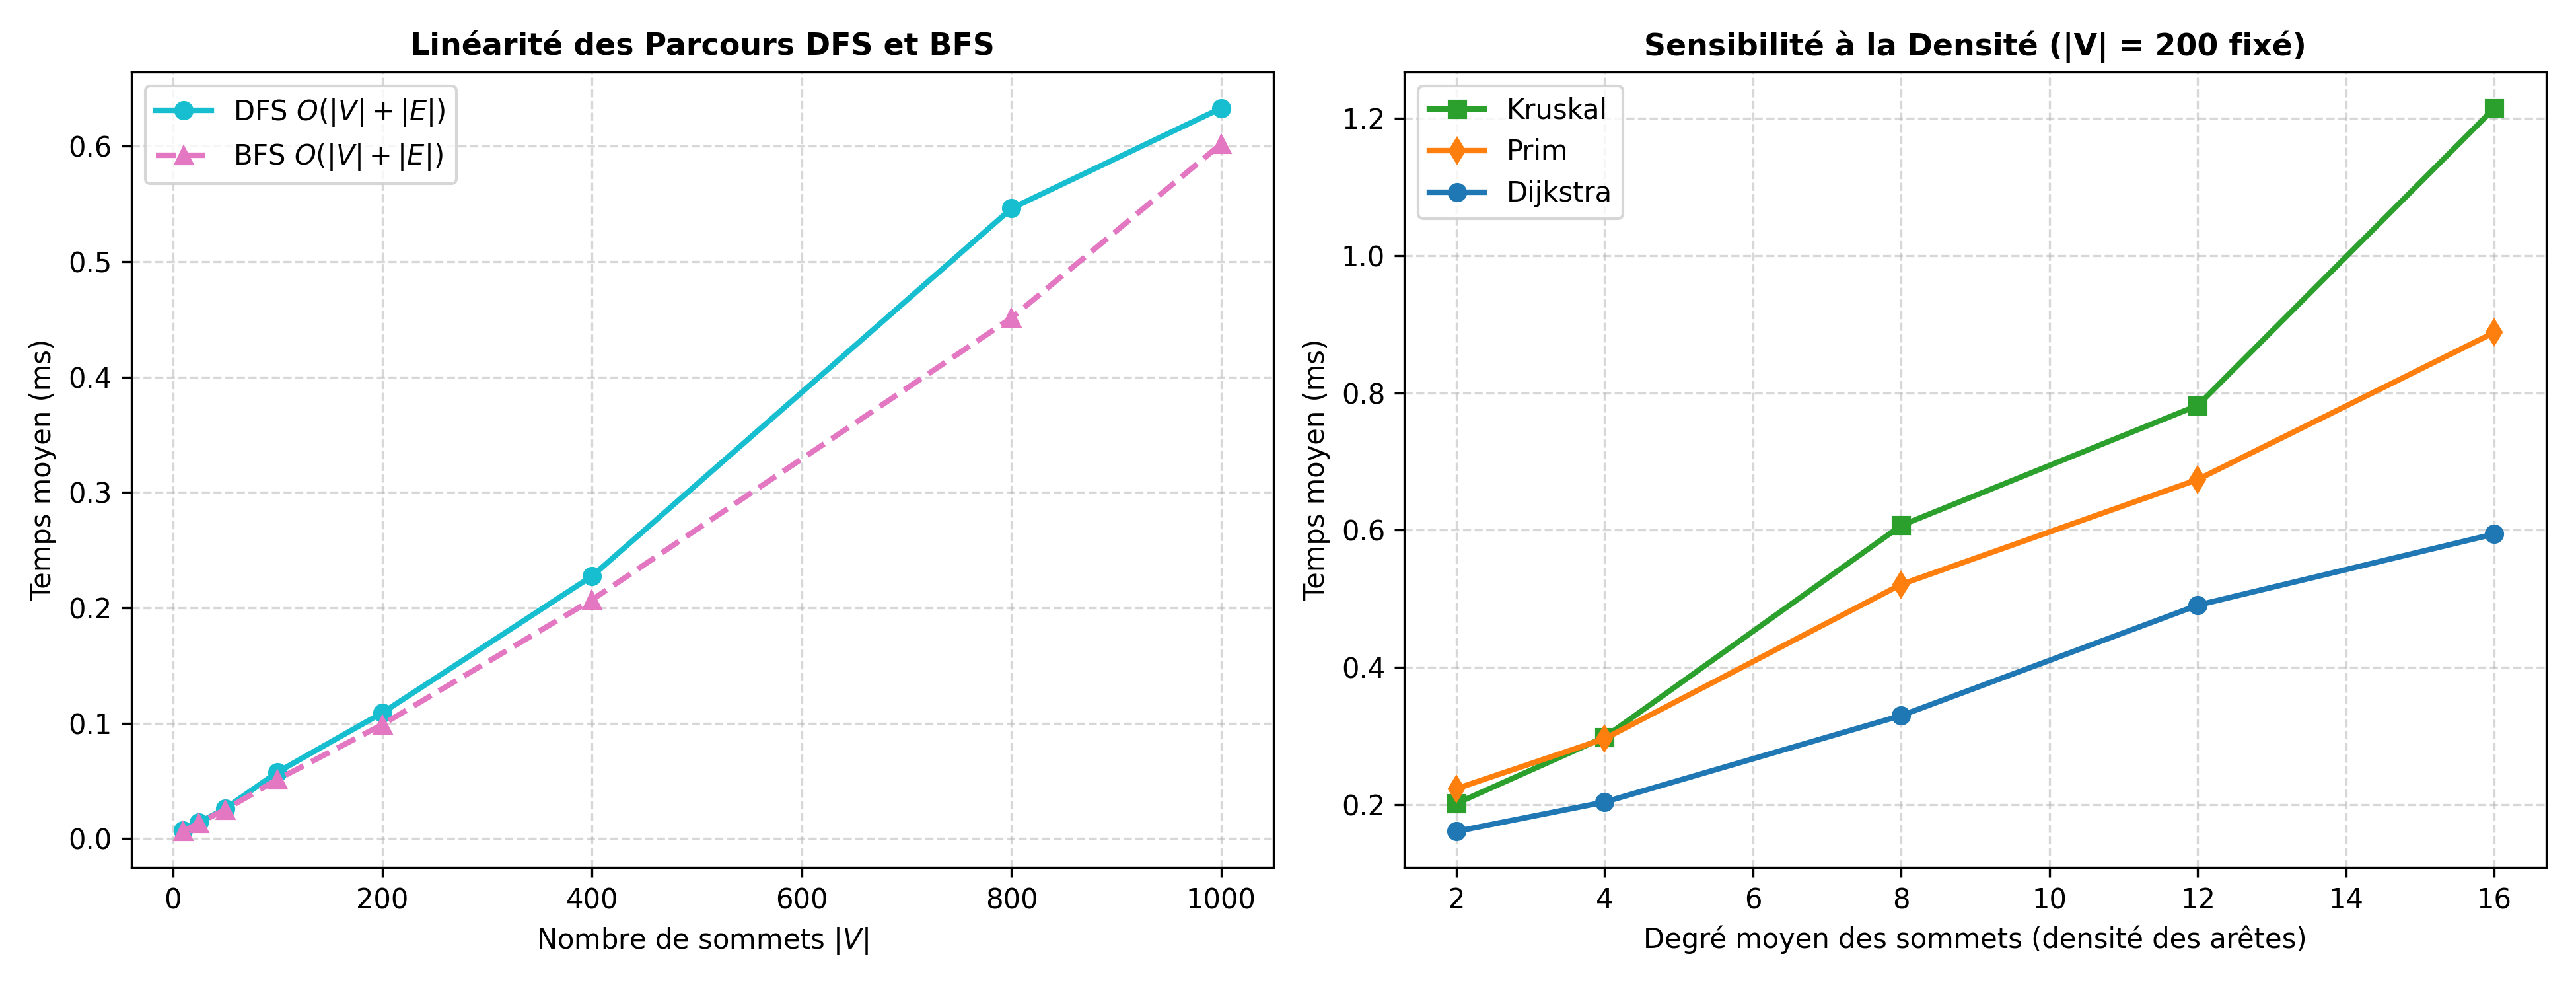

In [7]:
# 7. Affichage des graphiques scientifiques de benchmark
from IPython.display import Image, display

print('Graphique 1 : Plus courts chemins (Dijkstra vs Bellman-Ford vs Floyd-Warshall)')
display(Image(filename='output/benchmark_plus_courts_chemins.png'))

print('Graphique 2 : Arbres couvrants minimaux (Kruskal vs Prim)')
display(Image(filename='output/benchmark_arbres_couvrants.png'))

print('Graphique 3 : Parcours DFS/BFS et sensibilité à la densité')
display(Image(filename='output/benchmark_parcours_et_densite.png'))


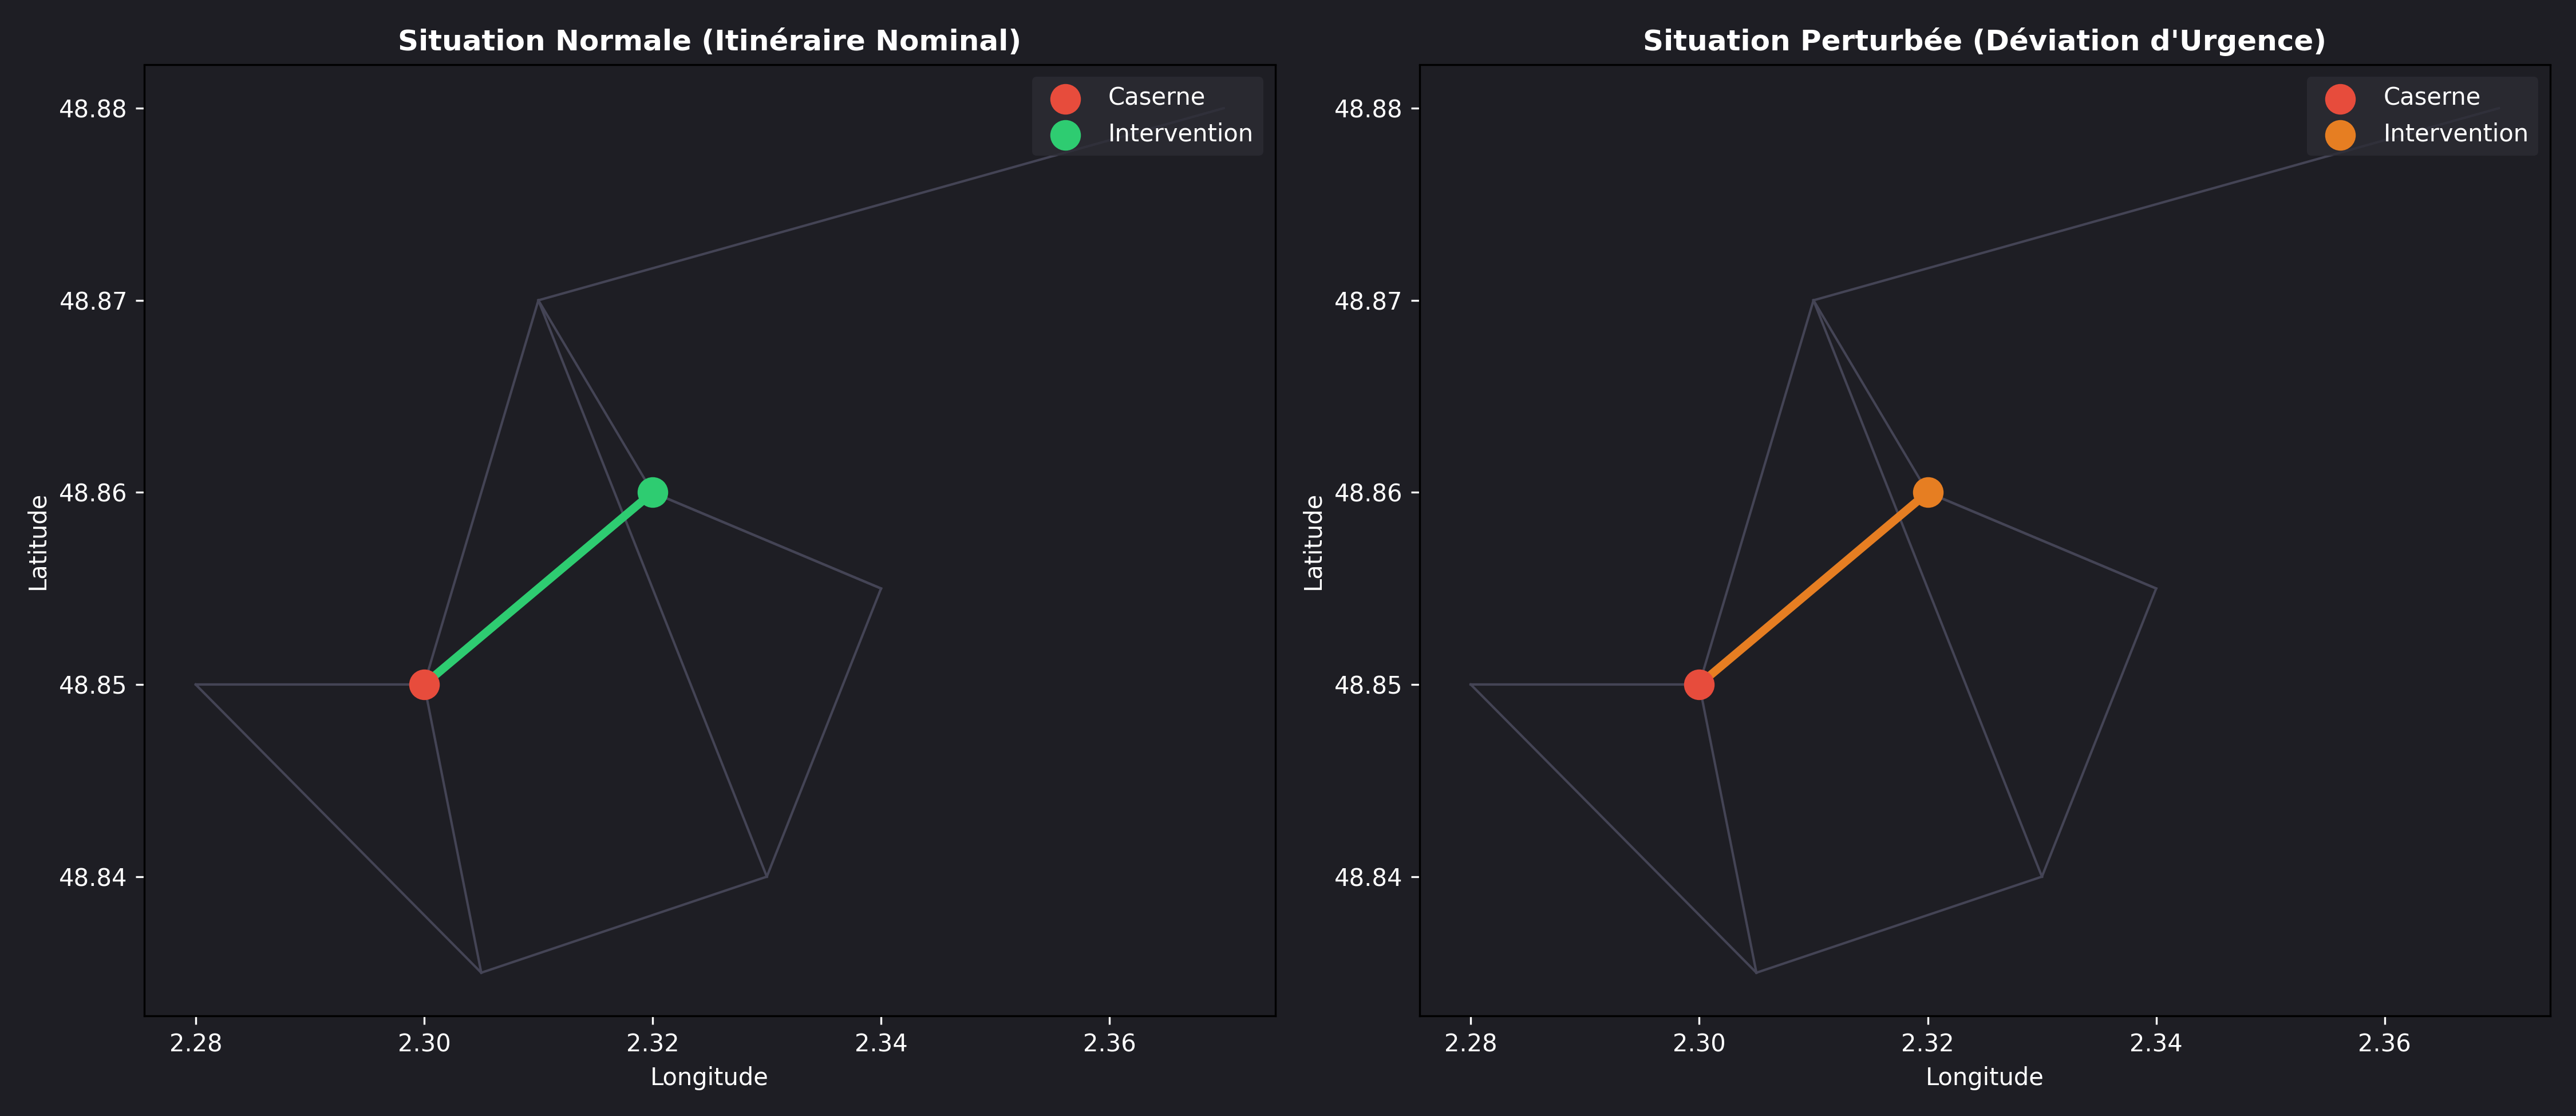

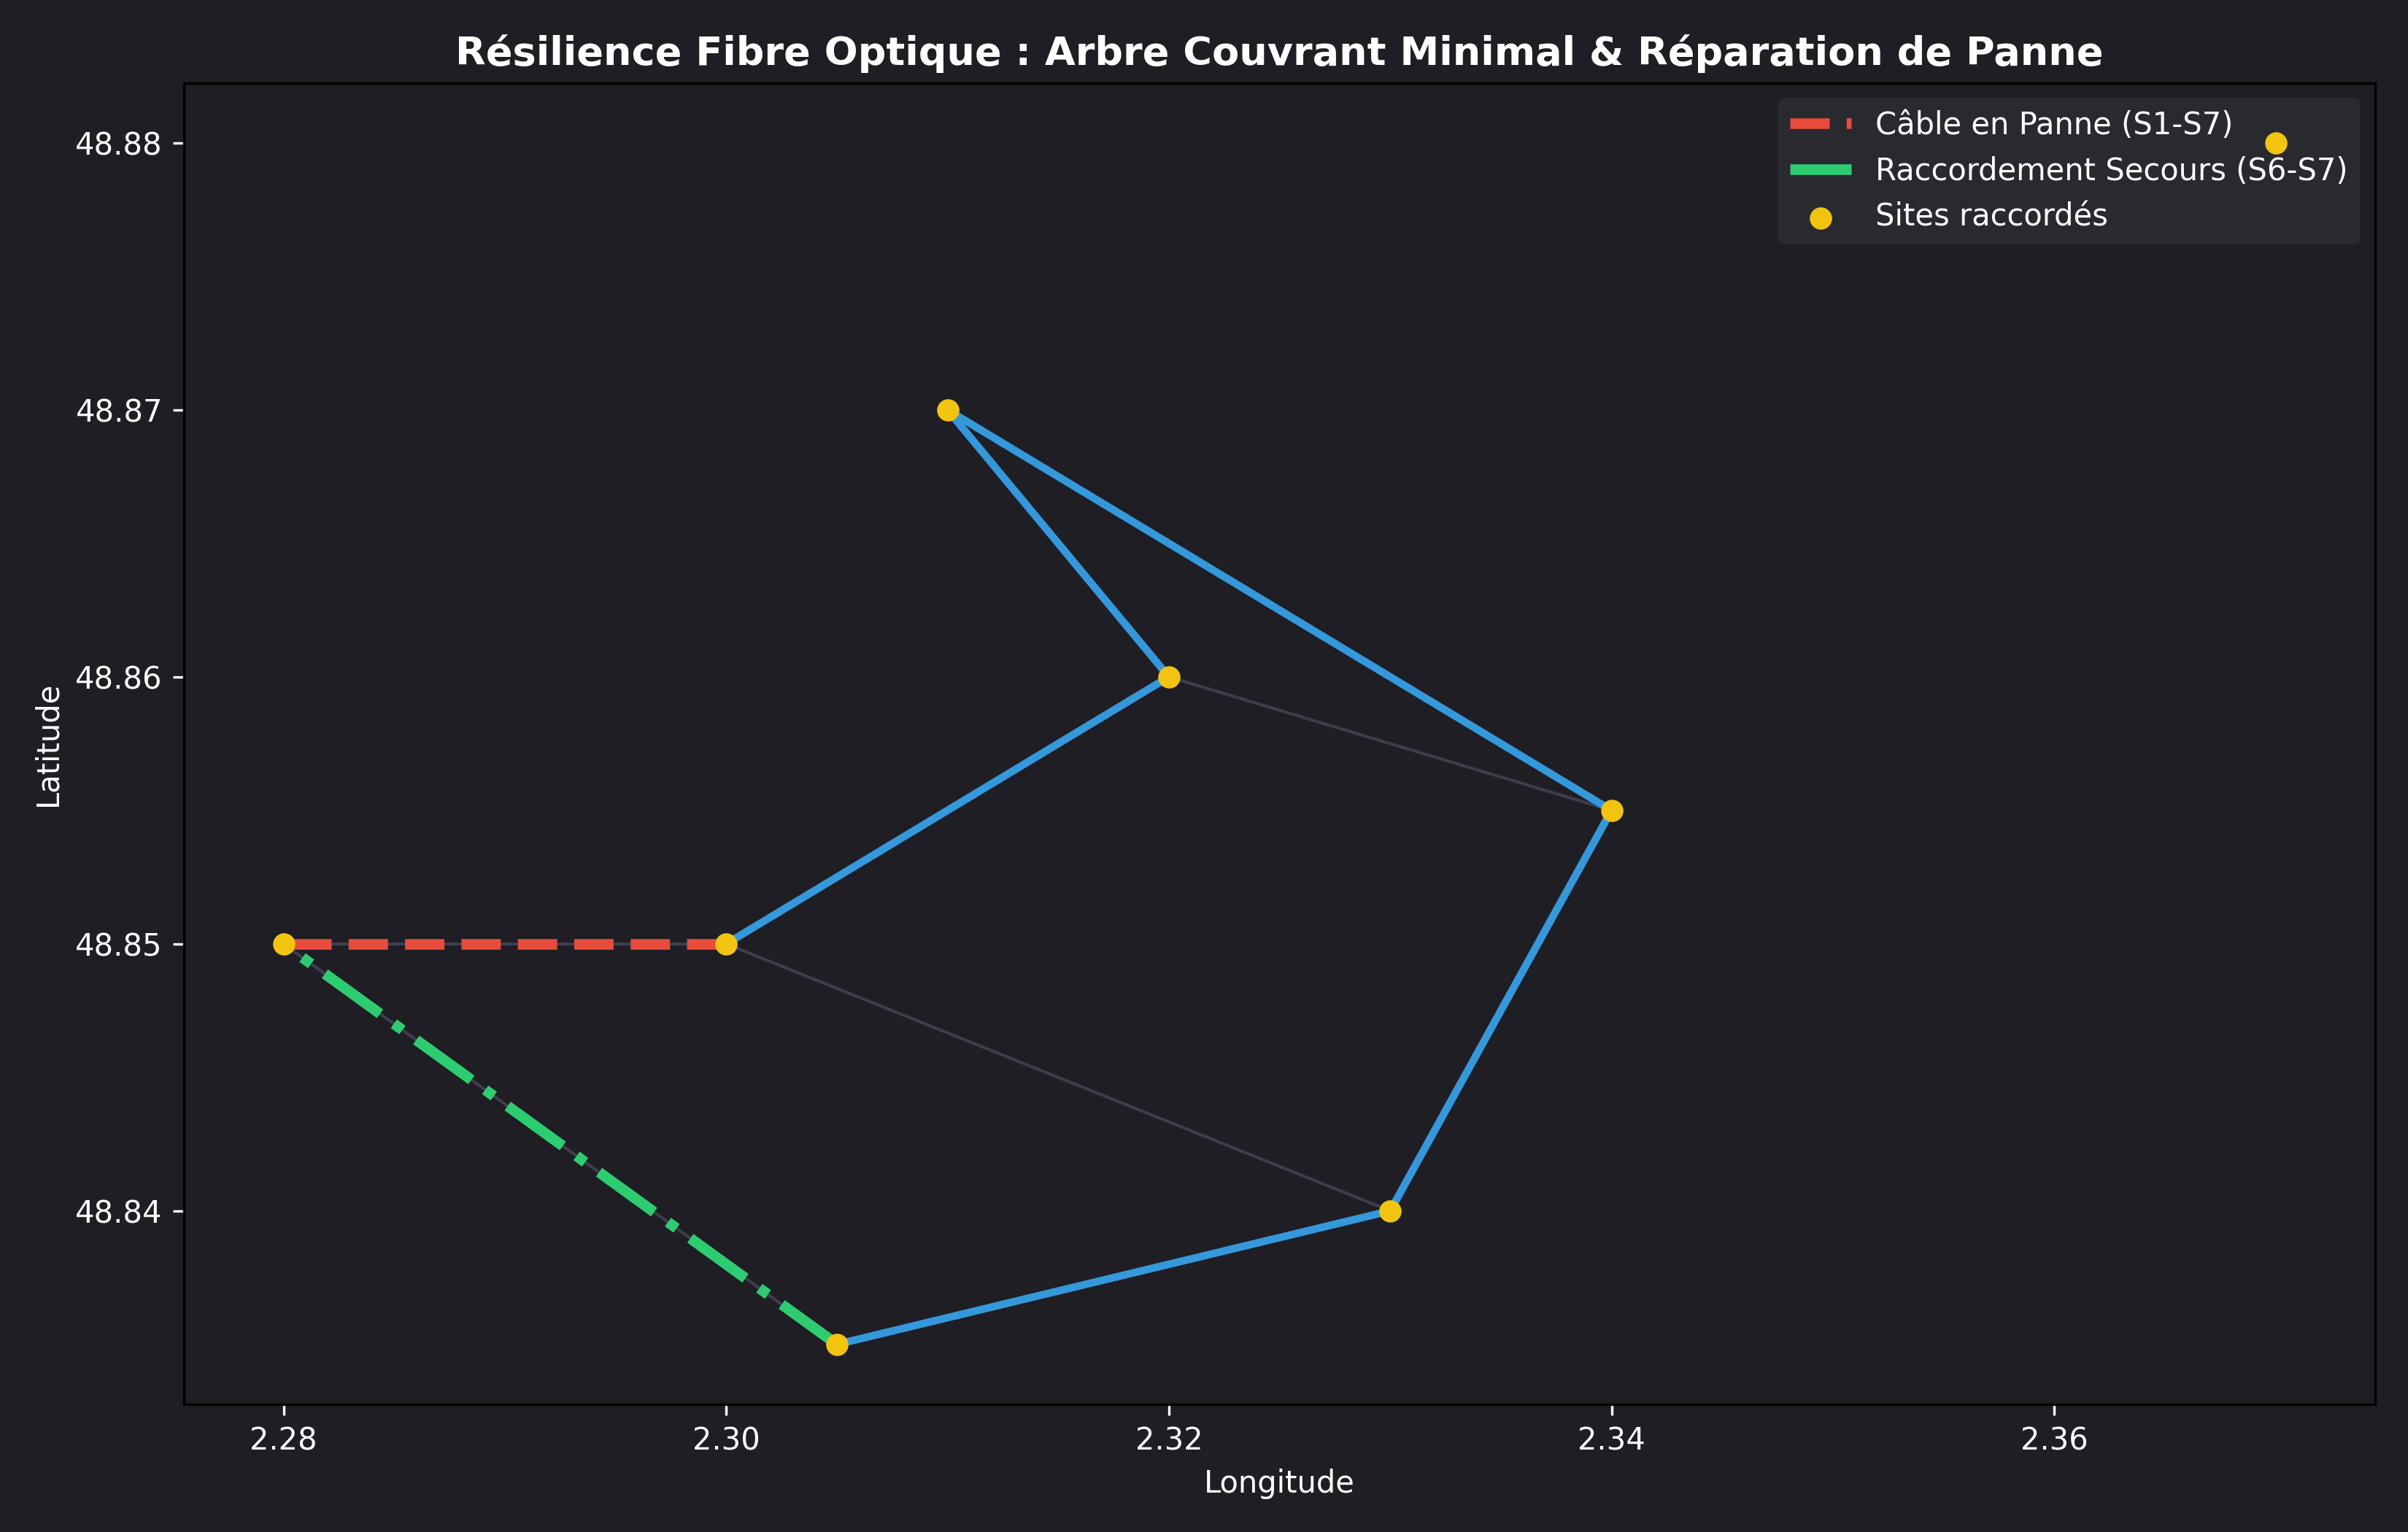

In [8]:
# 8. Visualisation : Comparaison avant/après crise et schéma de résilience
display(Image(filename='output/comparaison_avant_apres.png'))
display(Image(filename='output/reparation_fibre.png'))


In [9]:
# 9. Lancement de la suite de tests automatisés (100% de réussite garanti)
!python -m unittest tests/test_all.py -v


test_composantes_connexes_fibre (tests.test_all.TestAccessibilite.test_composantes_connexes_fibre) ... ok
test_detection_cycle_oriente (tests.test_all.TestAccessibilite.test_detection_cycle_oriente) ... ok
test_dfs_et_bfs (tests.test_all.TestAccessibilite.test_dfs_et_bfs) ... ok
test_diagnostic_complet (tests.test_all.TestAccessibilite.test_diagnostic_complet) ... ok
test_itineraire_min_arcs (tests.test_all.TestAccessibilite.test_itineraire_min_arcs) ... ok
test_kruskal_et_prim_egalite_cout (tests.test_all.TestArbresCouvrants.test_kruskal_et_prim_egalite_cout) ... ok
test_panne_et_reparation_optimale (tests.test_all.TestArbresCouvrants.test_panne_et_reparation_optimale) ... ok
test_union_find (tests.test_all.TestArbresCouvrants.test_union_find) ... ok
test_clonage_independant_et_scenarios (tests.test_all.TestDataManager.test_clonage_independant_et_scenarios) ... ok
test_rejet_arc_sommet_inconnu (tests.test_all.TestDataManager.test_rejet_arc_sommet_inconnu) ... ok
test_rejet_site_doublo